###**Objetivos**

Uma das coisas mais legais que temos no Brasil é o acesso a dados disponibilizados por fontes oficiais.

Com todos os desafios que nosso país enfrenta, qualquer pessoa com um pouco de boa vontade pode ter acesso a um grande número de datasets que podem servir como fonte de estudo e até mesmo uma importante fonte de informação independente sobre os mais variados assuntos de nosso país.

O portal brasileiro de dados aberto é sem dúvida alguma um grande parque de diversão para quem gosta de analisar dados

Neste notebook resolvi pegar os dados dos candidadtos às eleições do ano de 2022. O foco central foram os candidatos à Presidência da República e Deputado Federal

In [32]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

sns.set()

###**Importando os dados**

In [33]:
temp = ['SQ_CANDIDATO', 'NM_CANDIDATO','NM_TIPO_ELEICAO', 'SG_UE', 'DS_CARGO', 'DS_SITUACAO_CANDIDATURA', 'NM_UE', 'SG_PARTIDO', 'DS_ESTADO_CIVIL', 'DS_GENERO', 'DS_GRAU_INSTRUCAO', 'DS_COR_RACA']
bens = ['SQ_CANDIDATO', 'ANO_ELEICAO', 'DS_TIPO_BEM_CANDIDATO', 'VR_BEM_CANDIDATO']
df = pd.read_csv('bem_candidato_2022_BRASIL.csv', encoding='ISO-8859-1', sep=';')
df_cand = pd.read_csv('bem_candidato_2022_BRASIL.csv', encoding='ISO-8859-1', sep=';', usecols=bens)
df_bens = pd.read_csv('consulta_cand_2022_BRASIL.csv', encoding='ISO-8859-1', sep=';', usecols=temp)

###**Situação dos candidatos**

Selecionei apenas candidatos que estavam aptos ou cadastrados

Existem candidatos que estão com status de inapto. Pelo sim pelo não, resolvi não perder tempo tentando entender o porquê da situação e acabei filtrando apenas os candidatos que estão com status de **Apto** ou **Cadastrado**

In [34]:
(df_bens['DS_SITUACAO_CANDIDATURA'].value_counts(normalize=True).round(2)) * 100

DS_SITUACAO_CANDIDATURA
APTO      90.0
INAPTO    10.0
Name: proportion, dtype: float64

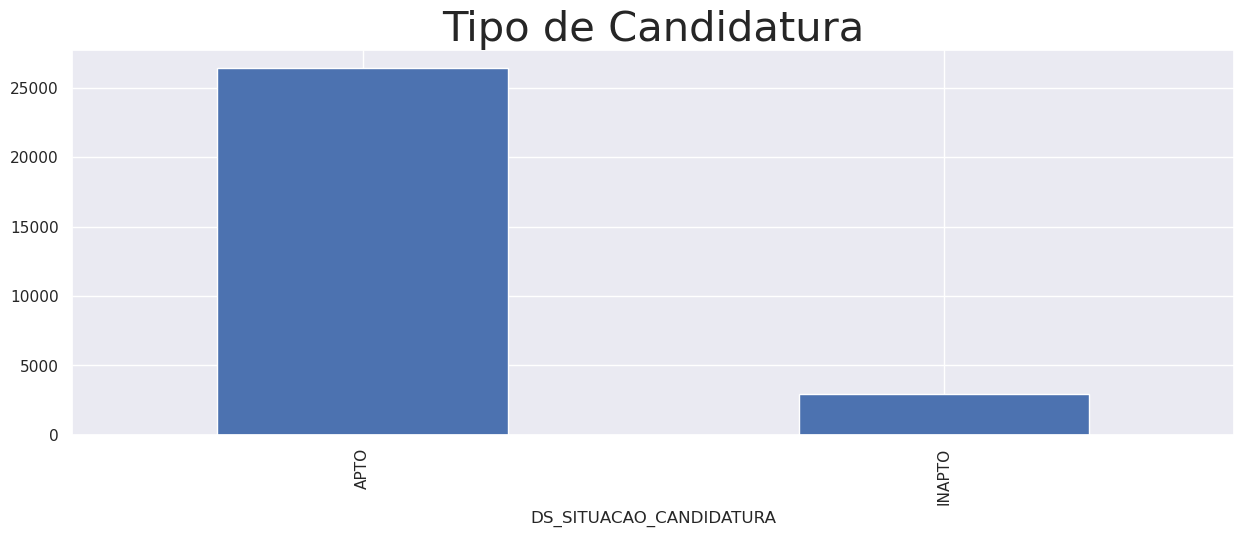

In [35]:
df_bens['DS_SITUACAO_CANDIDATURA'].value_counts().plot(kind='bar', figsize=(15,5))
plt.title('Tipo de Candidatura', fontdict={'fontsize':30});

In [36]:
df_bens = df_bens.query('DS_SITUACAO_CANDIDATURA == "APTO" or DS_SITUACAO_CANDIDATURA == "CADASTRADO"')
df_bens['DS_SITUACAO_CANDIDATURA'].value_counts()

DS_SITUACAO_CANDIDATURA
APTO    26409
Name: count, dtype: int64

In [37]:
df_bens['DS_CARGO'].value_counts()

DS_CARGO
DEPUTADO ESTADUAL     15257
DEPUTADO FEDERAL       9476
DEPUTADO DISTRITAL      571
GOVERNADOR              229
VICE-GOVERNADOR         229
2º SUPLENTE             208
SENADOR                 207
1º SUPLENTE             206
PRESIDENTE               13
VICE-PRESIDENTE          13
Name: count, dtype: int64

###**Candidatos a presidência**

In [38]:
presidente = df_bens.query('DS_CARGO == "PRESIDENTE"')
presidente['DS_CARGO'].value_counts()


DS_CARGO
PRESIDENTE    13
Name: count, dtype: int64

In [39]:
df_bens[df_bens['DS_CARGO'] == "PRESIDENTE"].value_counts()

NM_TIPO_ELEICAO    SG_UE  NM_UE   DS_CARGO    SQ_CANDIDATO  NM_CANDIDATO                         DS_SITUACAO_CANDIDATURA  SG_PARTIDO  DS_GENERO  DS_GRAU_INSTRUCAO            DS_ESTADO_CIVIL  DS_COR_RACA
ELEIÇÃO ORDINÁRIA  BR     BRASIL  PRESIDENTE  280001607829  LUIZ INÁCIO LULA DA SILVA            APTO                     PT          MASCULINO  ENSINO FUNDAMENTAL COMPLETO  CASADO(A)        BRANCA         2
                                              280001618036  JAIR MESSIAS BOLSONARO               APTO                     PL          MASCULINO  SUPERIOR COMPLETO            CASADO(A)        BRANCA         2
                                              280001600167  SOFIA PADUA MANZANO                  APTO                     PCB         FEMININO   SUPERIOR COMPLETO            SOLTEIRO(A)      BRANCA         1
                                              280001602702  LEONARDO PÉRICLES VIEIRA ROQUE       APTO                     UP          MASCULINO  ENSINO MÉDIO COMPLETO       

In [40]:
df_bens.query('DS_CARGO == "PRESIDENTE"')[['NM_CANDIDATO', 'SG_PARTIDO']].sort_values(by='NM_CANDIDATO')

,NM_CANDIDATO,SG_PARTIDO
20248,CIRO FERREIRA GOMES,PDT
2000,JAIR MESSIAS BOLSONARO,PL
5619,JAIR MESSIAS BOLSONARO,PL
20247,JOSE MARIA EYMAEL,DC
27656,KELMON LUIS DA SILVA SOUZA,PTB
27657,LEONARDO PÉRICLES VIEIRA ROQUE,UP
9266,LUIZ FELIPE CHAVES D AVILA,NOVO
16589,LUIZ INÁCIO LULA DA SILVA,PT
23986,LUIZ INÁCIO LULA DA SILVA,PT
1999,SIMONE NASSAR TEBET,MDB


###**Grau de instrução dos candidatos**

Note-se que a grande quantidade dos candidatos possui ensino superior. Isso pode indicar que a qualidade dos governos tende a melhorar por conta do maior grau instrução. 

In [41]:
presidente['DS_GRAU_INSTRUCAO'].value_counts()

DS_GRAU_INSTRUCAO
SUPERIOR COMPLETO              10
ENSINO FUNDAMENTAL COMPLETO     2
ENSINO MÉDIO COMPLETO           1
Name: count, dtype: int64

###**Superior Completo**

In [42]:
presidente.query('DS_GRAU_INSTRUCAO == "SUPERIOR COMPLETO"')['NM_CANDIDATO'].sort_values()

20248                    CIRO FERREIRA GOMES
2000                  JAIR MESSIAS BOLSONARO
5619                  JAIR MESSIAS BOLSONARO
20247                      JOSE MARIA EYMAEL
27656             KELMON LUIS DA SILVA SOUZA
9266              LUIZ FELIPE CHAVES D AVILA
1999                     SIMONE NASSAR TEBET
9265                     SOFIA PADUA MANZANO
27659                SORAYA VIEIRA THRONICKE
27658    VERA LUCIA PEREIRA DA SILVA SALGADO
Name: NM_CANDIDATO, dtype: object

In [43]:
presidente.query('DS_GRAU_INSTRUCAO == "ENSINO FUNDAMENTAL COMPLETO"')['NM_CANDIDATO']

16589    LUIZ INÁCIO LULA DA SILVA
23986    LUIZ INÁCIO LULA DA SILVA
Name: NM_CANDIDATO, dtype: object

In [44]:
presidente.query('DS_GRAU_INSTRUCAO == "ENSINO MÉDIO COMPLETO"')['NM_CANDIDATO']

27657    LEONARDO PÉRICLES VIEIRA ROQUE
Name: NM_CANDIDATO, dtype: object

###**Bens dos candidatos**

Para verificar os bens dos candidatos, acabei tendo que fazer um merge entre duas tabelas

Com estes dados consegui também identificar o tipo de aplicação financeira que cada candidato declarou

In [45]:
patrimonio = presidente.merge(df_cand, how = 'left')

In [46]:
patrimonio.head(3)

,NM_TIPO_ELEICAO,SG_UE,NM_UE,DS_CARGO,SQ_CANDIDATO,NM_CANDIDATO,DS_SITUACAO_CANDIDATURA,SG_PARTIDO,DS_GENERO,DS_GRAU_INSTRUCAO,DS_ESTADO_CIVIL,DS_COR_RACA,ANO_ELEICAO,DS_TIPO_BEM_CANDIDATO,VR_BEM_CANDIDATO
0,ELEIÇÃO ORDINÁRIA,BR,BRASIL,PRESIDENTE,280001607833,SIMONE NASSAR TEBET,APTO,MDB,FEMININO,SUPERIOR COMPLETO,CASADO(A),BRANCA,2022,Apartamento,"81903,69"
1,ELEIÇÃO ORDINÁRIA,BR,BRASIL,PRESIDENTE,280001607833,SIMONE NASSAR TEBET,APTO,MDB,FEMININO,SUPERIOR COMPLETO,CASADO(A),BRANCA,2022,Apartamento,"310000,00"
2,ELEIÇÃO ORDINÁRIA,BR,BRASIL,PRESIDENTE,280001607833,SIMONE NASSAR TEBET,APTO,MDB,FEMININO,SUPERIOR COMPLETO,CASADO(A),BRANCA,2022,Apartamento,"200000,00"


In [47]:
patrimonio.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 166 entries, 0 to 165
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   NM_TIPO_ELEICAO          166 non-null    object
 1   SG_UE                    166 non-null    object
 2   NM_UE                    166 non-null    object
 3   DS_CARGO                 166 non-null    object
 4   SQ_CANDIDATO             166 non-null    int64 
 5   NM_CANDIDATO             166 non-null    object
 6   DS_SITUACAO_CANDIDATURA  166 non-null    object
 7   SG_PARTIDO               166 non-null    object
 8   DS_GENERO                166 non-null    object
 9   DS_GRAU_INSTRUCAO        166 non-null    object
 10  DS_ESTADO_CIVIL          166 non-null    object
 11  DS_COR_RACA              166 non-null    object
 12  ANO_ELEICAO              166 non-null    int64 
 13  DS_TIPO_BEM_CANDIDATO    166 non-null    object
 14  VR_BEM_CANDIDATO         166 non-null    o

In [48]:
patrimonio['VR_BEM_CANDIDATO'] = patrimonio['VR_BEM_CANDIDATO'].apply(lambda x: float(x.replace(',', '.')))

In [49]:
patrimonio.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 166 entries, 0 to 165
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   NM_TIPO_ELEICAO          166 non-null    object 
 1   SG_UE                    166 non-null    object 
 2   NM_UE                    166 non-null    object 
 3   DS_CARGO                 166 non-null    object 
 4   SQ_CANDIDATO             166 non-null    int64  
 5   NM_CANDIDATO             166 non-null    object 
 6   DS_SITUACAO_CANDIDATURA  166 non-null    object 
 7   SG_PARTIDO               166 non-null    object 
 8   DS_GENERO                166 non-null    object 
 9   DS_GRAU_INSTRUCAO        166 non-null    object 
 10  DS_ESTADO_CIVIL          166 non-null    object 
 11  DS_COR_RACA              166 non-null    object 
 12  ANO_ELEICAO              166 non-null    int64  
 13  DS_TIPO_BEM_CANDIDATO    166 non-null    object 
 14  VR_BEM_CANDIDATO         1

In [51]:
total = patrimonio['VR_BEM_CANDIDATO'].sum().round(2)
total

np.float64(57337063.07)

Aqui vale uma observação. O candidato a deputado federal que tem o maior patrimônio, supera a soma de todos os candidatos à presidência da república juntos.

In [57]:
dados = patrimonio.groupby(['NM_CANDIDATO'])['VR_BEM_CANDIDATO'].sum().sort_values(ascending=False).reset_index()
dados['VR_BEM_CANDIDATO'] = dados['VR_BEM_CANDIDATO'].apply(lambda x: f'R$ {x:,.2f}'.replace(',', ' ').replace('.', ',').replace('  ', '.'))
dados

,NM_CANDIDATO,VR_BEM_CANDIDATO
0,LUIZ FELIPE CHAVES D AVILA,"R$ 24 619 627,66"
1,LUIZ INÁCIO LULA DA SILVA,"R$ 14 847 451,56"
2,JOSE MARIA EYMAEL,"R$ 6 572 826,60"
3,JAIR MESSIAS BOLSONARO,"R$ 4 635 109,46"
4,CIRO FERREIRA GOMES,"R$ 3 039 761,97"
5,SIMONE NASSAR TEBET,"R$ 2 323 735,38"
6,SORAYA VIEIRA THRONICKE,"R$ 783 000,00"
7,SOFIA PADUA MANZANO,"R$ 498 000,00"
8,VERA LUCIA PEREIRA DA SILVA SALGADO,"R$ 8 805,00"
9,KELMON LUIS DA SILVA SOUZA,"R$ 8 548,13"


In [58]:
patrimonio['DS_TIPO_BEM_CANDIDATO'].value_counts().head(10)

DS_TIPO_BEM_CANDIDATO
Depósito bancário em conta corrente no País                     21
Apartamento                                                     19
Casa                                                            18
Quotas ou quinhões de capital                                   15
Caderneta de poupança                                           13
Terreno                                                         12
Veículo automotor terrestre: caminhão, automóvel, moto, etc.    12
Crédito decorrente de empréstimo                                 9
Ações (inclusive as provenientes de linha telefônica)            6
Dinheiro em espécie - moeda nacional                             4
Name: count, dtype: int64

In [60]:
def extrato_investimento(candidato):
    temp = patrimonio.query('NM_CANDIDATO == @candidato').groupby(['DS_TIPO_BEM_CANDIDATO']).sum().sort_values(by='VR_BEM_CANDIDATO', ascending=False).reset_index()[['DS_TIPO_BEM_CANDIDATO', 'VR_BEM_CANDIDATO']]
    
    total = temp['VR_BEM_CANDIDATO'].sum()
    print(f'R$ {total:,.2f}')
    temp['VR_BEM_CANDIDATO'] = temp['VR_BEM_CANDIDATO'].apply(lambda x: f'R$ {x:,.2f}'.replace(',', ' ').replace('.', ',').replace('  ', '.'))
    return temp

In [ ]:
extrato_investimento('')